# Diagnostics at the strategy timeframe: SPY, ES3, BTC

Do the return diagnostics support the strategy family each asset actually trades, **at the bar size and horizons
the strategy uses**? One notebook, three assets, same tests, one verdict table at the end:
**mean reversion / momentum / random walk**.

### Strategies tested

| asset | strategy (`config/selected_strategies.json`) | decision bar | key horizons (bars) |
|---|---|---|---|
| SPY | momentum, EMA 8 / 16, 8-bar return > 0.25 % | **120 min** | lookback 8, slow 16 |
| ES3 | mean reversion, z-window 16, entry z ≤ −1.25, exit ≥ 0.25, hold 4–20 | **120 min** | window 16, hold ≤ 20 |
| BTC | voting (BB %B 20 + stoch 14 = reversal votes, 12-bar return + volume = momentum votes), long/short | **30 min** | lag 12, hold ≤ 12 |

Every test runs on the strategy's own bars, split and parameters.

### Data and periods
* Bars: `AlgoGoneCrazy/results/market_bars_30m_through_261012.csv` (read only). 120-min decision bars are built
  exactly like `src/portfolio_simulation.py::_rule_based_signal`: within each session segment (lunch break and
  overnight start a new segment), group every 4 consecutive 30-min bars and keep the **last** bar's adjusted close.
  That gives 4 decision bars per session for both SPY (4 + 4 + 4 + 1) and ES3 (4 + 2 | 4 + 4).
  Returns between decision bars include the overnight gap, as the strategy's features do.
* Periods = the ones the strategies were selected on (`config/strategy_optimization.json`, `config/btc_strategy.json`).
  **October 2026 (the live / holdout window) is excluded everywhere.**

| asset | train (used for the verdict) | validation (sign check) | test |
|---|---|---|---|
| SPY | 2023-09-18 → 2025-09-30 | 2025-10-01 → 2026-09-30 | – |
| ES3 | 2026-07-06 → 2026-08-31 | 2026-09-01 → 2026-09-30 | – |
| BTC | 2023-09-17 → 2026-05-31 | 2026-06-01 → 2026-08-31 | 2026-09-01 → 2026-09-30 |

**ES3 caveat:** intraday ES3 data only starts 2026-07-06 (Yahoo's ~60-day intraday limit), so train is ~40 sessions
≈ 160 decision bars. Only large effects can be significant there; the pooled pre-holdout row (train + val) is shown too.

All t-stats are heteroskedasticity / autocorrelation robust (Newey–West HAC, Lo–MacKinlay z\*): intraday returns have
strong volatility clustering and overnight gaps, and plain tests would over-reject.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)

## 0. Settings: each strategy's bar size, periods, parameters and costs

In [2]:
HOLDOUT_START = pd.Timestamp("2026-10-01")          # live window, never used here

ASSETS = {
    "SPY": dict(
        instrument="spy_usd", bar_minutes=120, strategy="momentum (long/cash)",
        periods={"train": ("2023-09-18", "2025-10-01"), "val": ("2025-10-01", "2026-10-01")},
        # strategy parameters (config/selected_strategies.json)
        mom=dict(fast=8, slow=16, lookback=8, entry=0.0025, exit=0.0),
        mr=dict(window=16, entry_z=-1.25, exit_z=0.25),           # not traded; same window as ES3 for comparison
        horizons=[1, 4, 8, 16], vr_q=[2, 4, 8, 16, 32], main_h=8,
        # IBKR Pro Tiered: 0.0035 USD/share, min 0.35 -> ~0.05 bps per side on a 100k order; no slippage in the backtest
        round_trip_bps=2 * 0.0035 / 650 * 1e4, allow_short=False),
    "ES3": dict(
        instrument="sti_es3_sgd", bar_minutes=120, strategy="mean reversion (long/cash)",
        periods={"train": ("2026-07-06", "2026-09-01"), "val": ("2026-09-01", "2026-10-01")},
        mr=dict(window=16, entry_z=-1.25, exit_z=0.25, min_hold=4, max_hold=20),
        mom=dict(fast=8, slow=16, lookback=8, entry=0.0025, exit=0.0),  # not traded; SPY's rule for comparison
        horizons=[1, 4, 8, 16, 20], vr_q=[2, 4, 8, 16], main_h=8,
        round_trip_bps=2 * 8.0,                                    # IBKR SGX 0.08 % per side (min SGD 2.50)
        allow_short=False),
    "BTC": dict(
        instrument="btc_usdt", bar_minutes=30, strategy="voting: BB/stoch reversal + 12-bar return/volume momentum (long/short)",
        periods={"train": ("2023-09-17", "2026-06-01"), "val": ("2026-06-01", "2026-09-01"),
                 "test": ("2026-09-01", "2026-10-01")},
        mr=dict(window=20, bb_lo=0.1, stoch_lo=30, stoch_n=14),    # bb_pctb_20 <= 0.1 / stoch_k_14 <= 30 vote long
        mom=dict(lookback=12, fast=20, slow=50),                   # ret_lag_12 sign vote
        horizons=[1, 6, 12, 24], vr_q=[2, 6, 12, 24, 48], main_h=12,
        round_trip_bps=2 * 10.0,                                   # Binance 0.10 % per side
        allow_short=True),
}

### Load and build decision bars (read-only)

In [3]:
DATA_PATH = os.environ.get("FE5209_BARS_30M")   # or paste a full path


def find_bars():
    if DATA_PATH:
        return Path(DATA_PATH)
    name = "market_bars_30m_through_261012.csv"
    for base in (Path.cwd(), *Path.cwd().parents):
        for cand in (base / "results" / name, base / "AlgoGoneCrazy" / "results" / name):
            if cand.exists():
                return cand
    raise FileNotFoundError(f"{name} not found - set DATA_PATH")


path = find_bars()
raw = pd.read_csv(path, usecols=["instrument_id", "bar_open_time_utc", "session_date_local", "bar_origin",
                                 "quality_status", "adjusted_close", "close", "high", "low"])
raw["t"] = pd.to_datetime(raw["bar_open_time_utc"], utc=True).dt.tz_convert(None)
raw = raw[raw["t"] < HOLDOUT_START].sort_values(["instrument_id", "t"]).reset_index(drop=True)
print("loaded:", path.name, raw.shape)


def decision_bars(bars, minutes):
    """Same construction as src/portfolio_simulation.py::_rule_based_signal."""
    b = bars.copy()
    if minutes == 30:
        return b
    factor = minutes // 30
    gap = b["t"].diff()
    seg = gap.ne(pd.Timedelta(minutes=30)) | b["session_date_local"].ne(b["session_date_local"].shift())
    b["_seg"] = seg.cumsum()
    b["_blk"] = b.groupby("_seg").cumcount() // factor
    return b.groupby(["_seg", "_blk"]).tail(1).drop(columns=["_seg", "_blk"]).reset_index(drop=True)


D = {}
for a, cfg in ASSETS.items():
    b = raw[raw["instrument_id"] == cfg["instrument"]]
    db = decision_bars(b, cfg["bar_minutes"]).set_index("t")
    db["logp"] = np.log(db["adjusted_close"])
    db["ret"] = db["logp"].diff()
    D[a] = db
    sessions = db["session_date_local"].nunique()
    print(f"{a}: {len(b):,} 30-min bars -> {len(db):,} {cfg['bar_minutes']}-min decision bars, "
          f"{sessions} sessions/days, {db.index.min()} -> {db.index.max()}, "
          f"non-complete bars: {int((db['bar_origin'] != 'derived_complete').sum())}")


def sl(x, a, p):
    if p == "pre-holdout":
        return x.loc[:HOLDOUT_START - pd.Timedelta(seconds=1)]
    s, e = ASSETS[a]["periods"][p]
    return x.loc[pd.Timestamp(s): pd.Timestamp(e) - pd.Timedelta(seconds=1)]


def periods(a):
    return list(ASSETS[a]["periods"]) + ["pre-holdout"]


rows = []
for a in ASSETS:
    for p in periods(a):
        r = sl(D[a]["ret"], a, p).dropna()
        rows.append({"asset": a, "period": p, "bars": len(r), "from": r.index.min().date(), "to": r.index.max().date(),
                     "mean (bps/bar)": r.mean() * 1e4, "std (bps/bar)": r.std() * 1e4,
                     "kurtosis": r.kurt(), "round-trip cost (bps)": ASSETS[a]["round_trip_bps"]})
pd.DataFrame(rows).set_index(["asset", "period"]).round(2)

loaded: market_bars_30m_through_261012.csv (73746, 10)
SPY: 9,864 30-min bars -> 3,034 120-min decision bars, 762 sessions/days, 2023-09-18 15:00:00 -> 2026-09-30 19:30:00, non-complete bars: 0
ES3: 868 30-min bars -> 248 120-min decision bars, 62 sessions/days, 2026-07-06 02:30:00 -> 2026-09-30 08:30:00, non-complete bars: 6
BTC: 53,280 30-min bars -> 53,280 30-min decision bars, 1110 sessions/days, 2023-09-17 00:00:00 -> 2026-09-30 23:30:00, non-complete bars: 0


bars        from          to  mean (bps/bar)  std (bps/bar)  kurtosis  round-trip cost (bps)
asset period                                                                                                    
SPY   train         2033  2023-09-18  2025-09-30            2.12          47.86     17.71                   0.11
      val           1000  2025-10-01  2026-09-30            1.46          40.37      3.13                   0.11
      pre-holdout   3033  2023-09-18  2026-09-30            1.90          45.52     15.18                   0.11
ES3   train          159  2026-07-06  2026-08-31            5.39          40.30     11.66                  16.00
      val             88  2026-09-01  2026-09-30           -1.00          31.08      2.21                  16.00
      pre-holdout    247  2026-07-06  2026-09-30            3.11          37.34     10.20                  16.00
BTC   train        47423  2023-09-17  2026-05-31            0.22          36.23     15.62                  20.00
      val           4416  2026-06-01  2026-08-31            0.15          31.54     23.37                  20.00
      test          1440  2026-09-01  2026-09-30            0.43          27.55     15.93                  20.00
      pre-holdout  53279  2023-09-17  2026-09-30            0.22          35.66     16.19                  20.00

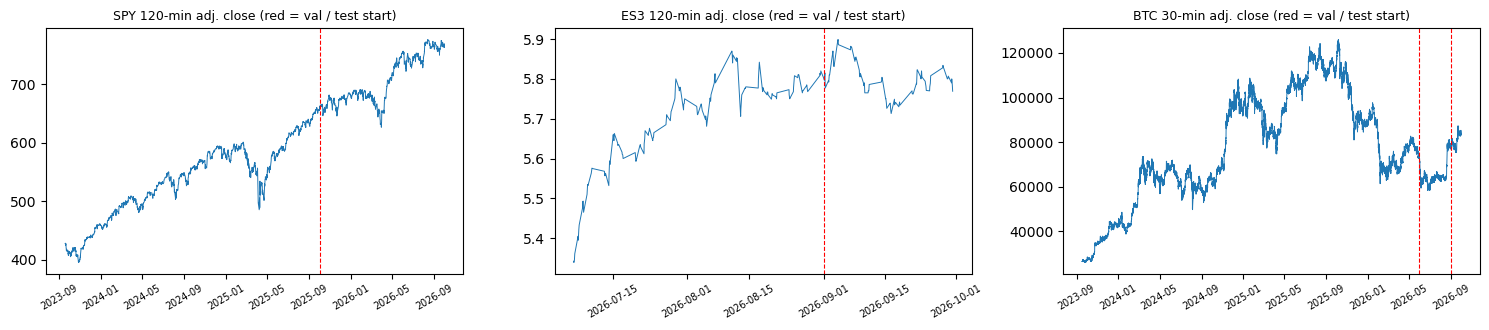

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for k, a in enumerate(ASSETS):
    s = D[a]["adjusted_close"]
    ax[k].plot(s.index, s.values, lw=0.7)
    for p in list(ASSETS[a]["periods"])[1:]:
        ax[k].axvline(pd.Timestamp(ASSETS[a]["periods"][p][0]), color="r", ls="--", lw=0.8)
    ax[k].set_title(f"{a} {ASSETS[a]['bar_minutes']}-min adj. close (red = val / test start)", fontsize=9)
    ax[k].tick_params(axis="x", labelsize=7, rotation=30)
plt.tight_layout(); plt.show()

In [5]:
def hac_slope(y, x, lags):
    d = pd.concat([y, x], axis=1).dropna()
    d.columns = ["y", "x"]
    if len(d) < 20:
        return np.nan, np.nan, len(d)
    m = sm.OLS(d["y"], sm.add_constant(d["x"])).fit(cov_type="HAC", cov_kwds={"maxlags": max(int(lags), 1)})
    return m.params["x"], m.tvalues["x"], len(d)


def variance_ratio(r, q):
    """Lo-MacKinlay VR(q), overlapping sums, heteroskedasticity-robust z*."""
    x = np.asarray(r, dtype=float)
    x = x[~np.isnan(x)]
    T = len(x)
    if T < 4 * q:
        return np.nan, np.nan
    mu = x.mean()
    s1 = ((x - mu) ** 2).sum() / (T - 1)
    xq = pd.Series(x).rolling(q).sum().dropna().to_numpy()
    m = q * (T - q + 1) * (1 - q / T)
    vr = ((xq - q * mu) ** 2).sum() / m / s1
    d = (x - mu) ** 2
    theta = sum((2 * (q - j) / q) ** 2 * (d[j:] * d[:-j]).sum() / d.sum() ** 2 * T for j in range(1, q))
    return vr, np.sqrt(T) * (vr - 1) / np.sqrt(theta)


def hurst_lagvar(lp, max_lag):
    tau = np.arange(1, max_lag + 1)
    v = np.array([lp.diff(t).var() for t in tau])
    return np.polyfit(np.log(tau), np.log(v), 1)[0] / 2


def fwd(a, h):
    lp = D[a]["logp"]
    return lp.shift(-h) - lp


def label(t, neg="MR", pos="MOM"):
    if np.isnan(t):
        return "n/a"
    return f"{neg} (sig.)" if t < -1.96 else f"{pos} (sig.)" if t > 1.96 else "n.s."

In [6]:
# ---- figure style: one look for every chart below ------------------------------------------------
# colour carries ONE meaning everywhere: blue = mean-reversion side, red = momentum side, grey = not significant.
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

MR_C, MOM_C, NS_C = "#2a78d6", "#e34948", "#b5b3ab"      # blue / red / neutral grey
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
VOL_C = "#6250d6"                                           # violet: volatility (|r|, r^2), never direction
DIV_CMAP = LinearSegmentedColormap.from_list("mr_mom", [MR_C, "#f0efec", MOM_C])

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelsize": 8.5, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5, "legend.frameon": False,
    "font.family": "DejaVu Sans", "lines.linewidth": 2,
})

SAVE_FIGS = True                                   # PNGs for the slides; set False to keep the notebook read-only
FIG_DIR = Path.cwd() / "figures" / "diagnostics_3assets"


def finish(fig, name, source):
    fig.text(0.01, 0.005, source, fontsize=6.5, color=MUTED, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    if SAVE_FIGS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def side_color(t, sign_val=None):
    """negative statistic = MR side; |t| > 1.96 coloured, otherwise grey"""
    if np.isnan(t) or abs(t) <= 1.96:
        return NS_C
    return MR_C if t < 0 else MOM_C


def bar_label(a):
    return f"{a} · {ASSETS[a]['bar_minutes']}-min bars · train"

## 1. Autocorrelation of decision-bar returns

$r_t = a + \rho_k r_{t-k}$ with HAC t-stats. **ρ < 0 → reversal (MR), ρ > 0 → continuation (momentum).**
Lags are in decision bars (SPY / ES3: 1 bar = 2 h of trading, 4 bars ≈ 1 session; BTC: 1 bar = 30 min).
The Ljung–Box p-value is the plain (non-robust) joint test up to that lag, shown for reference only.

In [7]:
rows = []
for a in ASSETS:
    lags = sorted(set([1, 2, 4] + [h for h in ASSETS[a]["horizons"] if h > 1]))
    for p in periods(a):
        r = sl(D[a]["ret"], a, p).dropna()
        lb = acorr_ljungbox(r, lags=lags)
        for k in lags:
            d = pd.concat([r, r.shift(k)], axis=1).dropna()
            rho, t, n = hac_slope(d.iloc[:, 0], d.iloc[:, 1], 5)
            rows.append({"asset": a, "period": p, "lag": k, "rho": rho, "HAC t": t, "reading": label(t),
                         "Ljung-Box p": lb["lb_pvalue"].get(k, np.nan)})
acf_tab = pd.DataFrame(rows)
acf_tab[acf_tab.period == "train"].set_index(["asset", "lag"]).drop(columns="period").round(4)

rho   HAC t    reading  Ljung-Box p
asset lag                                        
SPY   1    0.0395  0.9070       n.s.       0.0750
      2   -0.0303 -0.9081       n.s.       0.0808
      4    0.0104  0.1530       n.s.       0.0302
      8    0.0136  0.3500       n.s.       0.0069
      16   0.0020  0.0458       n.s.       0.0257
ES3   1   -0.1137 -3.0957  MR (sig.)       0.1479
      2   -0.0224 -0.4411       n.s.       0.3370
      4    0.0382  0.4249       n.s.       0.6595
      8   -0.0893 -0.5288       n.s.       0.7929
      16  -0.0657 -0.4527       n.s.       0.9384
      20  -0.0956 -0.7824       n.s.       0.9381
BTC   1   -0.0172 -1.7022       n.s.       0.0002
      2   -0.0110 -1.3179       n.s.       0.0001
      4    0.0040  0.6022       n.s.       0.0002
      6   -0.0089 -1.3282       n.s.       0.0000
      12   0.0016  0.2314       n.s.       0.0001
      24   0.0019  0.3112       n.s.       0.0029

In [8]:
# all periods (read val / test for the sign only)
acf_tab.pivot_table(index=["asset", "lag"], columns="period", values="HAC t", sort=False).round(2)

period     train   val  pre-holdout  test
asset lag                                
SPY   1     0.91 -0.80         0.64   NaN
      2    -0.91  0.84        -0.64   NaN
      4     0.15 -0.73        -0.00   NaN
      8     0.35 -0.62         0.13   NaN
      16    0.05  0.81         0.32   NaN
ES3   1    -3.10 -1.61        -3.27   NaN
      2    -0.44 -0.39        -0.42   NaN
      4     0.42  1.30         0.80   NaN
      8    -0.53 -1.49        -0.78   NaN
      16   -0.45 -1.32        -0.48   NaN
      20   -0.78 -1.40        -1.35   NaN
BTC   1    -1.70 -0.91        -1.91 -0.84
      2    -1.32 -0.92        -1.44  0.23
      4     0.60 -1.95         0.13 -0.07
      6    -1.33 -0.83        -1.48 -0.03
      12    0.23 -0.61         0.06 -0.97
      24    0.31 -0.09         0.24 -0.77

### Figure 1 — Correlogram with robust bands (L4: ACF)

Each stem is the lag-k autocorrelation of the strategy's own bar returns on train. The **shaded band** is the
HAC-robust 95 % band (±1.96 × Newey–West s.e. of ρ̂ₖ); the dashed lines are the textbook iid band ±1.96/√n from L4.
Stems outside the shaded band are coloured: **blue = reversal (MR side), red = continuation (momentum side)**.
The vertical tick marks each strategy's main horizon.

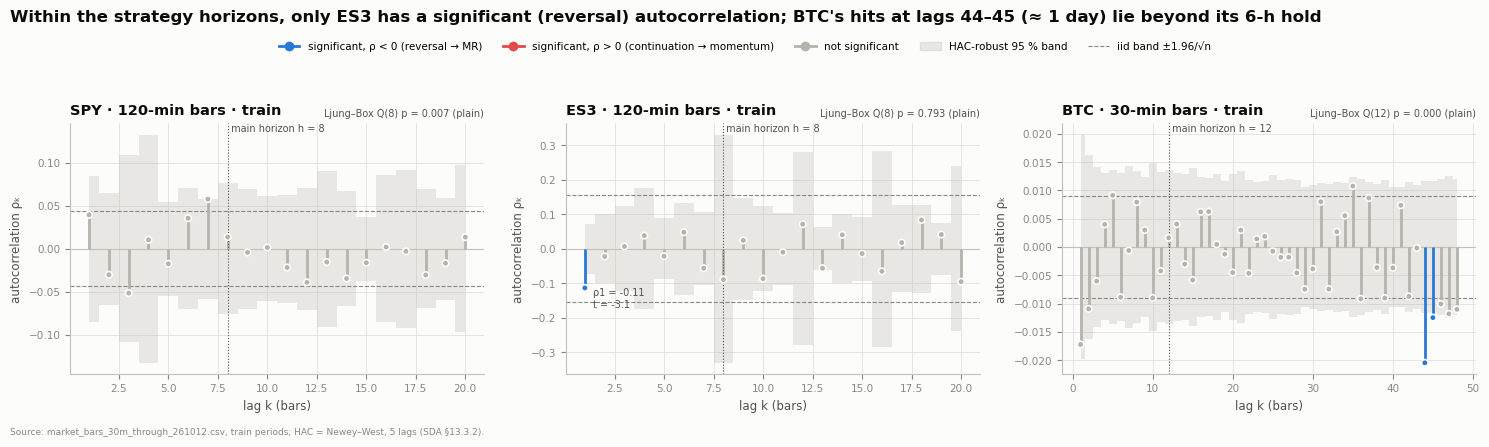

In [9]:
MAXLAG = {"SPY": 20, "ES3": 20, "BTC": 48}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, a in zip(axes, ASSETS):
    r = sl(D[a]["ret"], a, "train").dropna()
    lags = np.arange(1, MAXLAG[a] + 1)
    rho, se = [], []
    for k in lags:
        d = pd.concat([r, r.shift(k)], axis=1).dropna()
        m = sm.OLS(d.iloc[:, 0], sm.add_constant(d.iloc[:, 1])).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        rho.append(m.params.iloc[1]); se.append(m.bse.iloc[1])
    rho, se = np.array(rho), np.array(se)
    t = rho / se
    ax.fill_between(lags, -1.96 * se, 1.96 * se, color=NS_C, alpha=0.28, lw=0, step="mid", label="HAC 95 % band")
    iid = 1.96 / np.sqrt(len(r))
    ax.axhline(iid, color=MUTED, ls="--", lw=0.8); ax.axhline(-iid, color=MUTED, ls="--", lw=0.8)
    ax.axhline(0, color=AXIS, lw=0.8)
    cols = [side_color(x) for x in t]
    ax.vlines(lags, 0, rho, colors=cols, lw=2)
    ax.scatter(lags, rho, c=cols, s=22, zorder=3, edgecolors=SURF, linewidths=1.2)
    for k, rk, tk in zip(lags, rho, t):                       # label only the significant stems
        if abs(tk) > 1.96 and k <= 2 * ASSETS[a]["main_h"]:
            ax.annotate(f"ρ{k} = {rk:+.2f}\nt = {tk:.1f}", (k, rk), xytext=(6, -14 if rk < 0 else 4),
                        textcoords="offset points", fontsize=7, color=INK2)
    h = ASSETS[a]["main_h"]
    ax.axvline(h, color=INK2, lw=0.8, ls=":")
    ax.text(h, ax.get_ylim()[1], f" main horizon h = {h}", fontsize=7, color=INK2, va="top")
    lb = acorr_ljungbox(r, lags=[h])["lb_pvalue"].iloc[0]
    ax.set_title(bar_label(a))
    ax.text(1.0, 1.02, f"Ljung–Box Q({h}) p = {lb:.3f} (plain)", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=7, color=INK2)
    ax.set_xlabel("lag k (bars)"); ax.set_ylabel("autocorrelation ρₖ")
handles = [Line2D([], [], color=MR_C, marker="o", lw=2, label="significant, ρ < 0 (reversal → MR)"),
           Line2D([], [], color=MOM_C, marker="o", lw=2, label="significant, ρ > 0 (continuation → momentum)"),
           Line2D([], [], color=NS_C, marker="o", lw=2, label="not significant"),
           Patch(color=NS_C, alpha=0.28, label="HAC-robust 95 % band"),
           Line2D([], [], color=MUTED, ls="--", lw=0.8, label="iid band ±1.96/√n")]
fig.legend(handles=handles, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.07))
fig.suptitle("Within the strategy horizons, only ES3 has a significant (reversal) autocorrelation; BTC's hits at lags 44–45 (≈ 1 day) lie beyond its 6-h hold", x=0.01, ha="left",
             y=1.13, fontsize=12, fontweight="bold", color=INK)
finish(fig, "fig1_correlogram", "Source: market_bars_30m_through_261012.csv, train periods; HAC = Newey–West, 5 lags (SDA §13.3.2).")

### Figure 2 — Ljung–Box: direction vs volatility (L4 Ljung–Box, L6 GARCH)

Ljung–Box p-value for lags 1…K, on **returns** (is the direction predictable?) and on **squared returns**
(is the size predictable? the ARCH effect from L6). Below the 0.05 line = reject "no autocorrelation".
Squared returns are rejected almost everywhere: volatility clusters. That is exactly why every t-stat in this notebook
is HAC-robust: the plain Ljung–Box on returns over-rejects when variance clusters, so a low p on the solid line
is not, on its own, evidence of a tradable signal.

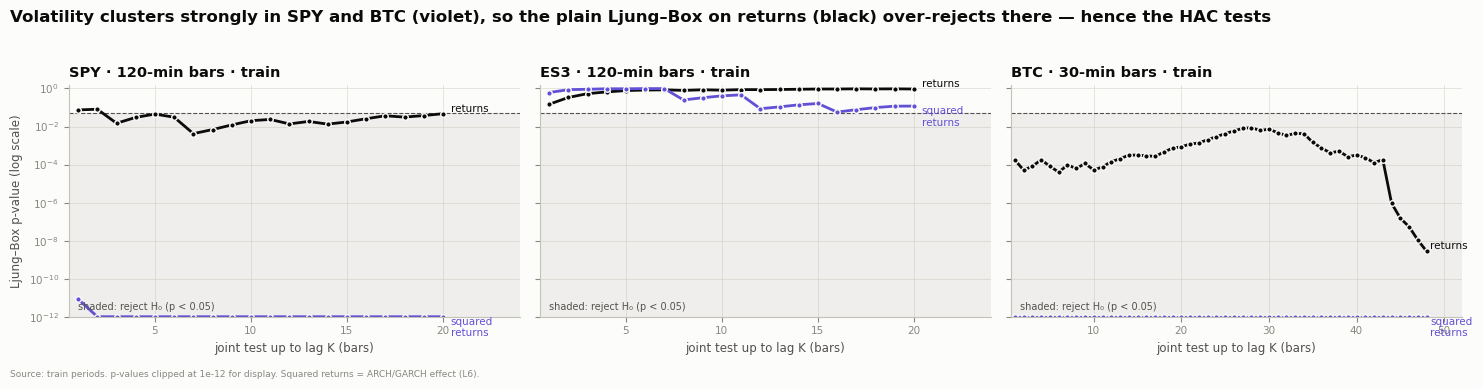

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, a in zip(axes, ASSETS):
    r = sl(D[a]["ret"], a, "train").dropna()
    K = MAXLAG[a]
    lags = list(range(1, K + 1))
    p_r = acorr_ljungbox(r, lags=lags)["lb_pvalue"].clip(lower=1e-12)
    p_v = acorr_ljungbox((r - r.mean()) ** 2, lags=lags)["lb_pvalue"].clip(lower=1e-12)
    ax.axhspan(1e-12, 0.05, color=NS_C, alpha=0.18, lw=0)
    ax.axhline(0.05, color=INK2, lw=0.8, ls="--")
    ax.plot(lags, p_r, color=INK, lw=2, marker="o", ms=4, mec=SURF, mew=1)
    ax.plot(lags, p_v, color=VOL_C, lw=2, marker="o", ms=4, mec=SURF, mew=1)
    ax.set_yscale("log"); ax.set_ylim(1e-12, 1.5)
    top_r = p_r.iloc[-1] >= p_v.iloc[-1]
    ax.text(K + 0.4, p_r.iloc[-1], "returns", color=INK, fontsize=7.5, va="bottom" if top_r else "top")
    ax.text(K + 0.4, p_v.iloc[-1], "squared\nreturns", color=VOL_C, fontsize=7.5, va="top" if top_r else "bottom")
    ax.text(0.02, 0.03, "shaded: reject H₀ (p < 0.05)", transform=ax.transAxes, fontsize=7, color=INK2)
    ax.set_xlim(0.5, K + 4)
    ax.set_title(bar_label(a)); ax.set_xlabel("joint test up to lag K (bars)")
axes[0].set_ylabel("Ljung–Box p-value (log scale)")
fig.suptitle("Volatility clusters strongly in SPY and BTC (violet), so the plain Ljung–Box on returns (black) over-rejects there — hence the HAC tests", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=INK, y=1.03)
finish(fig, "fig2_ljung_box_returns_vs_squared",
       "Source: train periods. p-values clipped at 1e-12 for display. Squared returns = ARCH/GARCH effect (L6).")

## 2. Variance ratio (Lo–MacKinlay, robust z\*)

$VR(q) = \operatorname{Var}(r_t+\dots+r_{t-q+1}) / (q\,\operatorname{Var}(r_t))$. Random walk: VR = 1.
**VR < 1 → MR, VR > 1 → momentum** over q bars. q covers each strategy's lookback and holding horizon.

In [11]:
rows = []
for a in ASSETS:
    for p in periods(a):
        r = sl(D[a]["ret"], a, p)
        for q in ASSETS[a]["vr_q"]:
            vr, z = variance_ratio(r, q)
            rows.append({"asset": a, "period": p, "q (bars)": q,
                         "q (hours)": q * ASSETS[a]["bar_minutes"] / 60, "VR": vr, "z*": z, "reading": label(z)})
vr_tab = pd.DataFrame(rows)
display(vr_tab[vr_tab.period == "train"].set_index(["asset", "q (bars)"]).drop(columns="period").round(3))
vr_tab.pivot_table(index=["asset", "q (bars)"], columns="period", values="VR", sort=False).round(3)

q (hours)     VR     z* reading
asset q (bars)                                 
SPY   2               4.0  1.040  0.915    n.s.
      4               8.0  1.006  0.073    n.s.
      8              16.0  0.994 -0.042    n.s.
      16             32.0  1.008  0.040    n.s.
      32             64.0  0.920 -0.295    n.s.
ES3   2               4.0  0.897 -1.875    n.s.
      4               8.0  0.841 -1.405    n.s.
      8              16.0  0.855 -0.765    n.s.
      16             32.0  0.664 -1.039    n.s.
BTC   2               1.0  0.983 -1.523    n.s.
      6               3.0  0.957 -1.832    n.s.
      12              6.0  0.951 -1.521    n.s.
      24             12.0  0.948 -1.215    n.s.
      48             24.0  0.929 -1.241    n.s.

period          train    val  pre-holdout   test
asset q (bars)                                  
SPY   2         1.040  0.973        1.023    NaN
      4         1.006  0.985        0.999    NaN
      8         0.994  0.990        0.990    NaN
      16        1.008  0.909        0.976    NaN
      32        0.920  0.910        0.903    NaN
ES3   2         0.897  0.902        0.899    NaN
      4         0.841  0.831        0.839    NaN
      8         0.855  0.968        0.866    NaN
      16        0.664  0.862        0.700    NaN
BTC   2         0.983  0.974        0.982  0.958
      6         0.957  0.939        0.955  0.928
      12        0.951  0.878        0.946  0.928
      24        0.948  0.867        0.943  1.007
      48        0.929  0.982        0.935  1.124

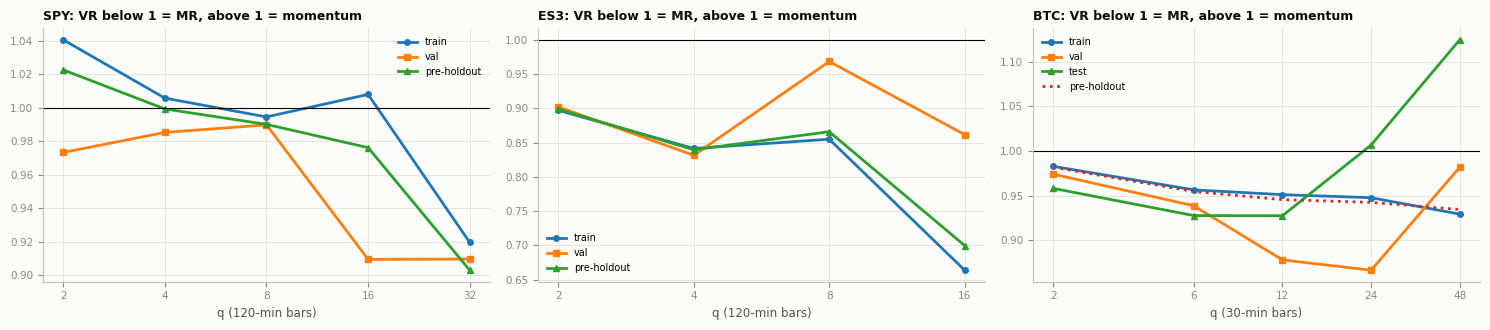

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for k, a in enumerate(ASSETS):
    for p, st in zip(periods(a), ("-o", "-s", "-^", ":")):
        s = vr_tab[(vr_tab.asset == a) & (vr_tab.period == p)]
        ax[k].plot(s["q (bars)"], s["VR"], st, label=p, ms=4)
    ax[k].axhline(1, color="k", lw=0.8)
    ax[k].set_xscale("log", base=2)
    ax[k].set_xticks(ASSETS[a]["vr_q"], [str(q) for q in ASSETS[a]["vr_q"]])
    ax[k].set_xlabel(f"q ({ASSETS[a]['bar_minutes']}-min bars)")
    ax[k].set_title(f"{a}: VR below 1 = MR, above 1 = momentum", fontsize=9)
    ax[k].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Hurst exponent (lag-variance) with a random-walk band

$\operatorname{Var}(p_{t+\tau}-p_t) \propto \tau^{2H}$ fitted for τ = 1 … max horizon. H < 0.5 = MR, H > 0.5 = trending.
The band is the 2.5–97.5 % range of the same estimator on 200 shuffled-return paths (a random walk of the same length
and return distribution) — a Hurst value inside the band is **not** evidence of anything.

In [13]:
rng = np.random.default_rng(0)
rows = []
for a in ASSETS:
    max_lag = max(ASSETS[a]["vr_q"])
    for p in periods(a):
        lp = sl(D[a]["logp"], a, p).dropna()
        r = lp.diff().dropna().to_numpy()
        h = hurst_lagvar(lp, max_lag)
        sims = [hurst_lagvar(pd.Series(np.cumsum(rng.permutation(r))), max_lag) for _ in range(200)]
        lo, hi = np.percentile(sims, [2.5, 97.5])
        rows.append({"asset": a, "period": p, "tau range (bars)": f"1-{max_lag}", "H": h,
                     "RW band low": lo, "RW band high": hi,
                     "reading": "MR (outside band)" if h < lo else "MOM (outside band)" if h > hi else "inside RW band"})
hurst_tab = pd.DataFrame(rows).set_index(["asset", "period"])
hurst_tab.round(3)

tau range (bars)      H  RW band low  RW band high         reading
asset period                                                                        
SPY   train                   1-32  0.482        0.445         0.545  inside RW band
      val                     1-32  0.478        0.415         0.562  inside RW band
      pre-holdout             1-32  0.480        0.459         0.534  inside RW band
ES3   train                   1-16  0.416        0.321         0.588  inside RW band
      val                     1-16  0.455        0.235         0.616  inside RW band
      pre-holdout             1-16  0.433        0.356         0.582  inside RW band
BTC   train                   1-48  0.493        0.487         0.511  inside RW band
      val                     1-48  0.493        0.459         0.533  inside RW band
      test                    1-48  0.525        0.418         0.554  inside RW band
      pre-holdout             1-48  0.494        0.489         0.509  inside RW band

## 4. Does the price level revert? ADF / KPSS and half-life

ADF H0: unit root. KPSS H0: stationary. A fixed-level mean reversion needs ADF reject **and** KPSS not reject.
The OU half-life ($-\ln 2 / b$ from $\Delta p_t = a + b\,p_{t-1}$) is in bars and hours; only meaningful when ADF rejects.
The strategies revert to a *rolling* mean, so section 5 is the more relevant test.

In [14]:
rows = []
for a in ASSETS:
    for p in periods(a):
        lp = sl(D[a]["logp"], a, p).dropna()
        adf_p = adfuller(lp, autolag="AIC")[1]
        kpss_p = kpss(lp, regression="c", nlags="auto")[1]
        d = pd.concat([lp.diff(), lp.shift(1)], axis=1).dropna()
        b = sm.OLS(d.iloc[:, 0], sm.add_constant(d.iloc[:, 1])).fit().params.iloc[1]
        hl = -np.log(2) / b if b < 0 else np.inf
        rows.append({"asset": a, "period": p, "ADF p": adf_p, "KPSS p": kpss_p,
                     "half-life (bars)": hl, "half-life (hours)": hl * ASSETS[a]["bar_minutes"] / 60,
                     "level reverts?": "yes" if (adf_p < 0.05 and kpss_p > 0.05) else "no (unit root)"})
adf_tab = pd.DataFrame(rows).set_index(["asset", "period"])
adf_tab.round(3)

ADF p  KPSS p  half-life (bars)  half-life (hours)  level reverts?
asset period                                                                         
SPY   train        0.757   0.010           879.489           1758.979  no (unit root)
      val          0.749   0.010           306.039            612.079  no (unit root)
      pre-holdout  0.742   0.010          1371.757           2743.514  no (unit root)
ES3   train        0.034   0.010            15.134             30.267  no (unit root)
      val          0.345   0.058             8.493             16.985  no (unit root)
      pre-holdout  0.001   0.010            15.243             30.485  no (unit root)
BTC   train        0.038   0.010          5335.618           2667.809  no (unit root)
      val          0.892   0.010          1334.830            667.415  no (unit root)
      test         0.697   0.010           310.425            155.213  no (unit root)
      pre-holdout  0.035   0.010          5343.516           2671.758  no (unit root)

### Figure 4 — Unit-root tests: ADF and KPSS side by side (L5)

L5's two tests ask opposite questions (ADF H₀: unit root; KPSS H₀: stationary), so reading them together gives a verdict. Filled dots = **log price**, hollow = **returns** (train). Grey region = the test rejects its H₀. The L5 story should appear:
prices land in "unit root" (no fixed level to revert to), returns land in "stationary" (difference-stationary, I(1)).
That is why the strategies revert to a *rolling* mean, not a fixed one.

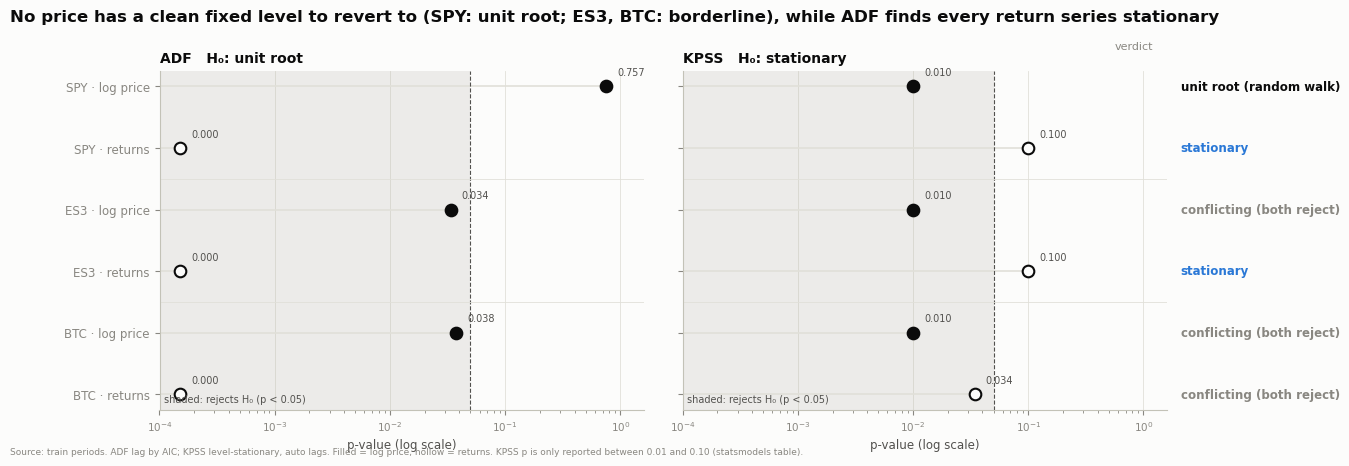

In [15]:
rows = []
for a in ASSETS:
    lp = sl(D[a]["logp"], a, "train").dropna()
    for name, series in (("log price", lp), ("returns", lp.diff().dropna())):
        adf_p = adfuller(series, autolag="AIC")[1]
        kpss_p = kpss(series, regression="c", nlags="auto")[1]
        if adf_p < 0.05 and kpss_p > 0.05:
            v = "stationary"
        elif adf_p >= 0.05 and kpss_p <= 0.05:
            v = "unit root (random walk)"
        elif adf_p < 0.05:
            v = "conflicting (both reject)"
        else:
            v = "inconclusive"
        rows.append((a, name, adf_p, kpss_p, v))

fig, (axA, axK) = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True, gridspec_kw={"wspace": 0.08})
ys = np.arange(len(rows))[::-1]
VCOL = {"stationary": MR_C, "unit root (random walk)": INK, "conflicting (both reject)": MUTED, "inconclusive": MUTED}
for ax, idx, title, xl in ((axA, 2, "ADF   H₀: unit root", "p-value (log scale)"),
                           (axK, 3, "KPSS   H₀: stationary", "p-value (log scale)")):
    ax.axvspan(1e-4, 0.05, color=NS_C, alpha=0.22, lw=0)
    ax.axvline(0.05, color=INK2, lw=0.8, ls="--")
    for y, row in zip(ys, rows):
        p = max(row[idx], 1.5e-4)
        filled = row[1] == "log price"
        ax.plot([1e-4, p], [y, y], color=GRID, lw=1.2, zorder=1)
        ax.scatter(p, y, s=70, facecolors=INK if filled else SURF, edgecolors=INK, linewidths=1.5, zorder=3)
        ax.text(p * 1.25, y + 0.18, f"{row[idx]:.3f}", fontsize=7, color=INK2)
    ax.set_xscale("log"); ax.set_xlim(1e-4, 1.6)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(xl)
    ax.text(0.01, 0.015, "shaded: rejects H₀ (p < 0.05)", transform=ax.transAxes, fontsize=7, color=INK2, va="bottom")
    ax.grid(axis="y", visible=False)
axA.set_yticks(ys, [f"{r[0]} · {r[1]}" for r in rows], fontsize=8.5)
for y, row in zip(ys, rows):
    axK.text(2.1, y, row[4], fontsize=8.5, va="center", color=VCOL[row[4]], fontweight="semibold",
             transform=axK.get_yaxis_transform() if False else axK.transData, clip_on=False)
for y in ys[1::2][:-1] - 0.5:
    axA.axhline(y, color=GRID, lw=0.6); axK.axhline(y, color=GRID, lw=0.6)
fig.suptitle("No price has a clean fixed level to revert to (SPY: unit root; ES3, BTC: borderline), while ADF finds every return series stationary",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK, y=1.02)
fig.text(0.86, 0.93, "verdict", fontsize=8, color=MUTED)
finish(fig, "fig4_unit_root_adf_kpss", "Source: train periods. ADF lag by AIC; KPSS level-stationary, auto lags. Filled = log price, hollow = returns. KPSS p is only reported between 0.01 and 0.10 (statsmodels table).")

### Figure 3 — Is the price path distinguishable from a random walk? (L5)

The random-walk model from L5, $Y_{t+1} = Y_t + \mu + \varepsilon_{t+1}$, simulated 1,000 times with a **wild bootstrap of
the asset's own train returns**: $\varepsilon^*_t = s_t (r_t-\bar r)$ with random signs $s_t=\pm1$. This keeps the drift, the fat
tails and the volatility clustering of the real data but removes any memory in the *direction* of moves. Bands = 50 % and 90 % of the simulated paths; black line = the
real path. Below the fan: the spread of the h-bar moves, real vs random-walk — under mean reversion the real moves are
*narrower* than the random walk's (VR < 1); under momentum, wider.

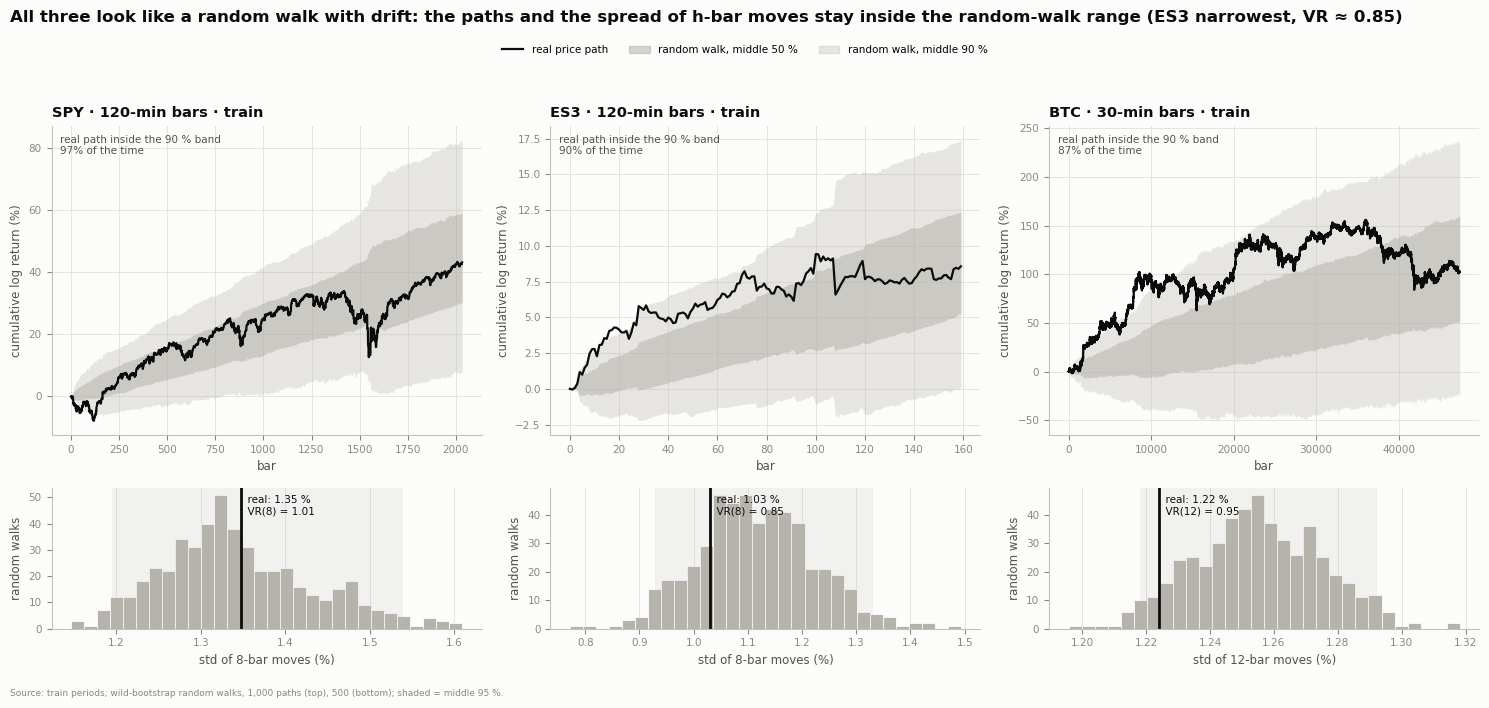

In [16]:
rng = np.random.default_rng(1)
fig, axes = plt.subplots(2, 3, figsize=(15, 6.4), gridspec_kw={"height_ratios": [2.2, 1]})
for k, a in enumerate(ASSETS):
    r = sl(D[a]["ret"], a, "train").dropna().to_numpy()
    mu, e = r.mean(), r - r.mean()
    wild = lambda: mu + e * rng.choice([-1.0, 1.0], size=len(e))
    real = np.concatenate([[0], np.cumsum(r)]) * 100
    sims = np.vstack([np.concatenate([[0], np.cumsum(wild())]) for _ in range(1000)]) * 100
    x = np.arange(len(real))
    ax = axes[0, k]
    ax.fill_between(x, *np.percentile(sims, [5, 95], axis=0), color=NS_C, alpha=0.30, lw=0)
    ax.fill_between(x, *np.percentile(sims, [25, 75], axis=0), color=NS_C, alpha=0.55, lw=0)
    ax.plot(x, real, color=INK, lw=1.6)
    lo90, hi90 = np.percentile(sims, [5, 95], axis=0)
    inside = ((real >= lo90) & (real <= hi90)).mean()
    ax.text(0.02, 0.97, f"real path inside the 90 % band\n{inside:.0%} of the time", transform=ax.transAxes,
            fontsize=7.5, color=INK2, va="top")
    ax.set_title(bar_label(a)); ax.set_xlabel("bar"); ax.set_ylabel("cumulative log return (%)")
    # bottom: dispersion of h-bar moves, real vs RW
    h = ASSETS[a]["main_h"]
    real_h = pd.Series(r).rolling(h).sum().dropna().std() * 100
    sim_h = [pd.Series(wild()).rolling(h).sum().dropna().std() * 100 for _ in range(500)]
    ax2 = axes[1, k]
    ax2.hist(sim_h, bins=30, color=NS_C, edgecolor=SURF, linewidth=0.6)
    lo, hi = np.percentile(sim_h, [2.5, 97.5])
    ax2.axvspan(lo, hi, color=NS_C, alpha=0.15, lw=0)
    c = MR_C if real_h < lo else MOM_C if real_h > hi else INK
    ax2.axvline(real_h, color=c, lw=2)
    ax2.text(real_h, ax2.get_ylim()[1] * 0.95, f"  real: {real_h:.2f} %\n  VR({h}) = {(real_h / np.mean(sim_h)) ** 2:.2f}",
             color=c if c != INK else INK, fontsize=7.5, va="top")
    ax2.set_xlabel(f"std of {h}-bar moves (%)"); ax2.set_ylabel("random walks"); ax2.grid(axis="y", visible=False)
handles = [Line2D([], [], color=INK, lw=1.6, label="real price path"),
           Patch(color=NS_C, alpha=0.55, label="random walk, middle 50 %"),
           Patch(color=NS_C, alpha=0.30, label="random walk, middle 90 %")]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
fig.suptitle("All three look like a random walk with drift: the paths and the spread of h-bar moves stay inside the random-walk range (ES3 narrowest, VR ≈ 0.85)",
             x=0.01, ha="left", y=1.08, fontsize=12, fontweight="bold", color=INK)
finish(fig, "fig3_random_walk_fan", "Source: train periods; wild-bootstrap random walks, 1,000 paths (top), 500 (bottom); shaded = middle 95 %.")

## 5. Strategy-signal tests with each strategy's own parameters

**5a. MR: rolling z-score → forward return.** $\log P_{t+h}-\log P_t = a + \beta z_t^{(W)}$, W = 16 bars for SPY / ES3
(the ES3 strategy's window), 20 bars for BTC (the window behind `bb_pctb_20`; %B is a linear function of this z).
**MR needs β < 0.** β is in bps of forward return per unit of z.

**5b. Momentum: past L-bar return → forward return.** $\log P_{t+h}-\log P_t = a + \beta R^{(L)}_t$, L = 8 bars for
SPY / ES3 (the SPY strategy's lookback), 12 bars for BTC (`ret_lag_12`). **Momentum needs β > 0.**

HAC lags = max(h, 5). h runs over each strategy's holding horizons; the **main horizon** (SPY 8, ES3 8, BTC 12 bars) is
the one used in the verdict. Overlapping forward windows in short samples (ES3, BTC test) inflate |t| — read those for sign.

In [17]:
def zscore(c, w):
    m, s = c.rolling(w).mean(), c.rolling(w).std(ddof=0)
    return (c - m) / s.where(s > 0)


rows = []
for a in ASSETS:
    c, lp = D[a]["adjusted_close"], D[a]["logp"]
    Z = zscore(c, ASSETS[a]["mr"]["window"])
    L = ASSETS[a]["mom"]["lookback"]
    R = lp.diff(L)
    for p in periods(a):
        for h in ASSETS[a]["horizons"]:
            y = sl(fwd(a, h), a, p)
            b, t, n = hac_slope(y * 1e4, sl(Z, a, p), max(h, 5))
            rows.append({"asset": a, "test": f"MR: z(W={ASSETS[a]['mr']['window']})", "period": p, "h": h,
                         "beta": b, "HAC t": t, "n": n, "reading": label(t)})
            b, t, n = hac_slope(y, sl(R, a, p), max(h, 5))
            rows.append({"asset": a, "test": f"MOM: R(L={L})", "period": p, "h": h,
                         "beta": b, "HAC t": t, "n": n, "reading": label(t)})
sig_tab = pd.DataFrame(rows)
sig_tab.pivot_table(index=["asset", "test", "h"], columns="period", values="HAC t", sort=False).round(2)

period                 train   val  pre-holdout  test
asset test         h                                 
SPY   MR: z(W=16)  1   -0.14 -0.89        -0.53   NaN
                   4   -0.21 -1.13        -0.66   NaN
                   8   -0.29 -1.47        -0.94   NaN
                   16  -0.70 -0.96        -1.04   NaN
      MOM: R(L=8)  1    0.50 -0.26         0.42   NaN
                   4    0.57 -0.99         0.25   NaN
                   8    0.16 -1.41        -0.35   NaN
                   16  -1.11 -0.53        -1.21   NaN
ES3   MR: z(W=16)  1   -1.78 -0.58        -1.43   NaN
                   4   -1.85  0.17        -1.06   NaN
                   8   -2.34 -0.52        -1.66   NaN
                   16  -2.08 -0.54        -1.26   NaN
                   20  -2.57 -0.82        -1.42   NaN
      MOM: R(L=8)  1   -1.44 -0.94        -1.34   NaN
                   4   -1.34 -0.58        -1.12   NaN
                   8   -1.45 -1.05        -1.28   NaN
                   16  -0.97 -0.62        -0.65   NaN
                   20  -0.74 -0.79        -0.47   NaN
BTC   MR: z(W=20)  1   -0.24 -0.35        -0.46 -1.07
                   6    0.29 -0.27         0.13 -0.52
                   12   0.04 -0.05         0.07  0.36
                   24   0.79  0.34         1.01  1.14
      MOM: R(L=12) 1   -1.24 -1.33        -1.48 -0.23
                   6   -0.48 -1.24        -0.68  0.77
                   12  -0.28 -0.36        -0.26  1.05
                   24  -0.57  0.80        -0.28  1.43

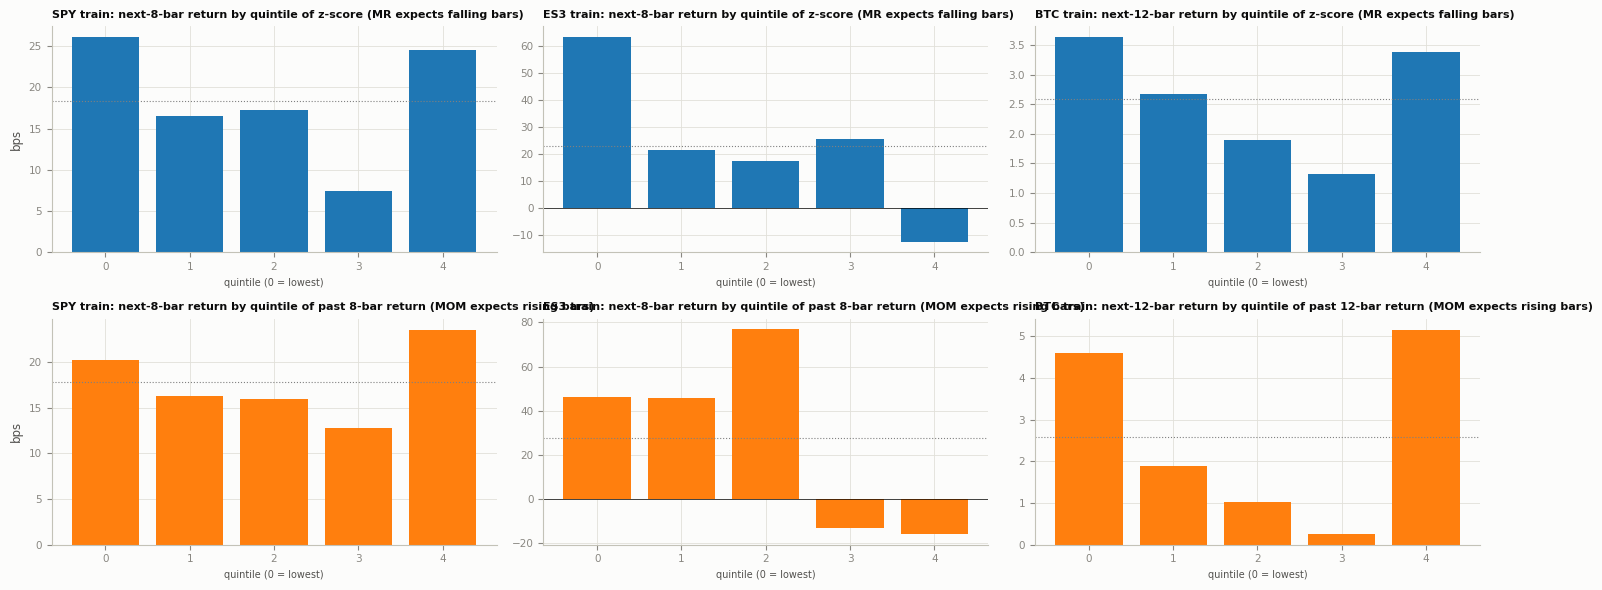

In [18]:
# picture: mean forward return (main horizon) by quintile of the signal, train period
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for k, a in enumerate(ASSETS):
    h = ASSETS[a]["main_h"]
    c, lp = D[a]["adjusted_close"], D[a]["logp"]
    sigs = {"z-score (MR expects falling bars)": zscore(c, ASSETS[a]["mr"]["window"]),
            f"past {ASSETS[a]['mom']['lookback']}-bar return (MOM expects rising bars)": lp.diff(ASSETS[a]["mom"]["lookback"])}
    for j, (name, s) in enumerate(sigs.items()):
        d = pd.concat([sl(s, a, "train"), sl(fwd(a, h), a, "train") * 1e4], axis=1).dropna()
        d.columns = ["s", "f"]
        g = d.groupby(pd.qcut(d["s"], 5, labels=False))["f"].mean()
        ax[j, k].bar(g.index, g.values, color="tab:blue" if j == 0 else "tab:orange")
        ax[j, k].axhline(d["f"].mean(), color="grey", ls=":", lw=0.8)
        ax[j, k].axhline(0, color="k", lw=0.5)
        ax[j, k].set_title(f"{a} train: next-{h}-bar return by quintile of {name}", fontsize=8)
        ax[j, k].set_xlabel("quintile (0 = lowest)", fontsize=7)
ax[0, 0].set_ylabel("bps"); ax[1, 0].set_ylabel("bps")
plt.tight_layout(); plt.show()

### Figure 5 — Signal regressions with robust t-stats (L2 regression, SDA §13.3.2 HAC)

Both strategy-signal regressions from section 5, as t-stats on one axis. For both, a **negative slope means reversal**
(a high z-score or a big past gain is followed by a fall), so the axis reads the same way for every row:
**left = mean-reversion side, right = momentum side**. Solid dot = HAC (Newey–West) t; hollow ring = the plain OLS t
you'd get from L2 without the correction. The grey band is |t| < 1.96.

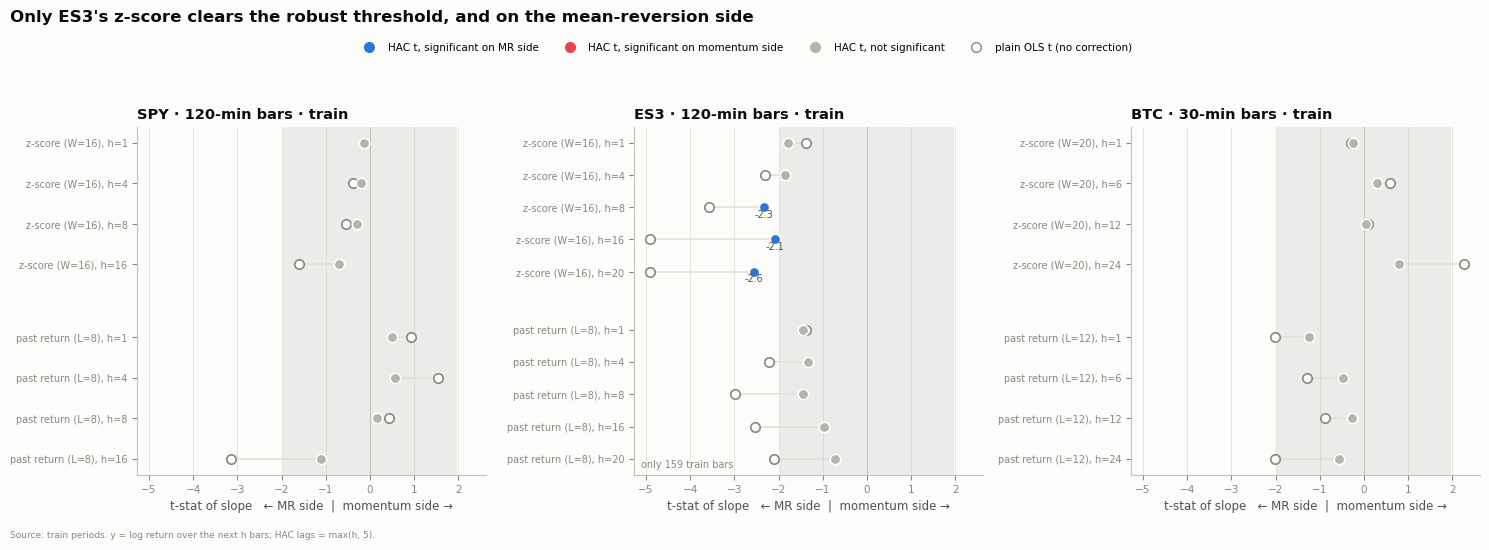

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True)
for ax, a in zip(axes, ASSETS):
    c, lp = D[a]["adjusted_close"], D[a]["logp"]
    W, L = ASSETS[a]["mr"]["window"], ASSETS[a]["mom"]["lookback"]
    sigs = [(f"z-score (W={W})", zscore(c, W)), (f"past return (L={L})", lp.diff(L))]
    rows, y = [], 0
    for name, s in sigs:
        for h in ASSETS[a]["horizons"]:
            d = pd.concat([sl(fwd(a, h), a, "train"), sl(s, a, "train")], axis=1).dropna()
            X = sm.add_constant(d.iloc[:, 1])
            t_hac = sm.OLS(d.iloc[:, 0], X).fit(cov_type="HAC", cov_kwds={"maxlags": max(h, 5)}).tvalues.iloc[1]
            t_ols = sm.OLS(d.iloc[:, 0], X).fit().tvalues.iloc[1]
            rows.append((y, name, h, t_hac, t_ols)); y += 1
        y += 0.8
    ax.axvspan(-1.96, 1.96, color=NS_C, alpha=0.22, lw=0)
    ax.axvline(0, color=AXIS, lw=0.8)
    for yy, name, h, th, to in rows:
        ax.plot([to, th], [yy, yy], color=GRID, lw=1.2, zorder=1)
        ax.scatter(to, yy, s=46, facecolors=SURF, edgecolors=MUTED, linewidths=1.2, zorder=2)
        ax.scatter(th, yy, s=56, color=side_color(th), edgecolors=SURF, linewidths=1.2, zorder=3)
        if abs(th) > 1.96:
            ax.text(th, yy + 0.32, f"{th:.1f}", fontsize=7, color=INK2, ha="center")
    ax.set_yticks([r[0] for r in rows], [f"{r[1]}, h={r[2]}" for r in rows], fontsize=7)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(bar_label(a)); ax.set_xlabel("t-stat of slope   ← MR side  |  momentum side →")
    if a == "ES3":
        ax.text(0.02, 0.02, f"only {len(sl(D[a]['ret'], a, 'train').dropna())} train bars", transform=ax.transAxes,
                fontsize=7, color=MUTED)
handles = [Line2D([], [], marker="o", ls="", color=MR_C, ms=7, label="HAC t, significant on MR side"),
           Line2D([], [], marker="o", ls="", color=MOM_C, ms=7, label="HAC t, significant on momentum side"),
           Line2D([], [], marker="o", ls="", color=NS_C, ms=7, label="HAC t, not significant"),
           Line2D([], [], marker="o", ls="", mfc=SURF, mec=MUTED, ms=7, label="plain OLS t (no correction)")]
fig.legend(handles=handles, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06))
fig.suptitle("Only ES3's z-score clears the robust threshold, and on the mean-reversion side",
             x=0.01, ha="left", y=1.11, fontsize=12, fontweight="bold", color=INK)
finish(fig, "fig5_signal_regressions_hac", "Source: train periods. y = log return over the next h bars; HAC lags = max(h, 5).")

## 6. Exact strategy rule: does the edge on entry beat the cost?

The entry condition of the rule each asset actually trades, reduced to **entry events** (first bar the condition turns on),
and the mean signed forward return over the main horizon before costs. For long-only rules the drift a random entry would
have earned over the same horizon is subtracted (`excess vs drift`), because SPY / ES3 / BTC all trended up in parts of
the sample.

* **SPY** momentum: fast EMA(8) > slow EMA(16) **and** 8-bar return > 0.25 %; h = 8 bars.
* **ES3** mean reversion: z(16) ≤ −1.25; h = 8 bars (and 20 = max hold).
* **BTC** voting legs separately: reversal leg (BB %B(20) ≤ 0.1 *and* stoch %K(14) ≤ 30 → long, mirror → short),
  momentum leg (sign of 12-bar return, entry when it flips), and the two agreeing (score ≥ 2 without the volume vote);
  h = 12 bars. The real strategy also needs a volatility-model gate and volume; this checks the price-based ingredients only.

In [20]:
def entries(cond):
    cond = cond.fillna(False).astype(bool)
    return cond & ~cond.shift(1, fill_value=False)


def event_stats(a, direction, h, p):
    f = fwd(a, h)
    d = pd.concat([direction, f], axis=1).dropna()
    d.columns = ["dir", "f"]
    d = sl(d, a, p)
    drift = sl(f, a, p).mean()
    e = d[d["dir"] != 0]
    s = e["dir"] * e["f"] * 1e4
    ex = s - e["dir"] * drift * 1e4
    n = len(s)
    return {"events": n, "mean signed bps": s.mean() if n else np.nan,
            "excess vs drift bps": ex.mean() if n else np.nan,
            "t (excess)": ex.mean() / ex.std(ddof=1) * np.sqrt(n) if n > 2 else np.nan,
            "hit rate": (s > 0).mean() if n else np.nan}


rules = []
# SPY momentum (traded)
c, lp = D["SPY"]["adjusted_close"], D["SPY"]["logp"]
pm = ASSETS["SPY"]["mom"]
ema_f = c.ewm(span=pm["fast"], adjust=False, min_periods=pm["fast"]).mean()
ema_s = c.ewm(span=pm["slow"], adjust=False, min_periods=pm["slow"]).mean()
spy_on = (ema_f > ema_s) & (c.pct_change(pm["lookback"]) > pm["entry"])
rules.append(("SPY", "momentum EMA8>EMA16 & R8>0.25% (traded)", entries(spy_on).astype(int), [8, 16]))
# SPY with the MR rule, for contrast
rules.append(("SPY", "MR z16<=-1.25 (not traded)", entries(zscore(c, 16) <= -1.25).astype(int), [8, 16]))
# ES3 MR (traded)
c3 = D["ES3"]["adjusted_close"]
rules.append(("ES3", "MR z16<=-1.25 (traded)", entries(zscore(c3, 16) <= -1.25).astype(int), [8, 20]))
ema_f3 = c3.ewm(span=8, adjust=False, min_periods=8).mean()
ema_s3 = c3.ewm(span=16, adjust=False, min_periods=16).mean()
rules.append(("ES3", "momentum EMA8>EMA16 & R8>0.25% (not traded)",
              entries((ema_f3 > ema_s3) & (c3.pct_change(8) > 0.0025)).astype(int), [8, 20]))
# BTC voting ingredients
db = D["BTC"]
cb = db["adjusted_close"]
pctb = (zscore(cb, 20) / 2 + 1) / 2                         # %B with 2-sd bands = 0.5 + z/4
low14, high14 = db["low"].rolling(14).min(), db["high"].rolling(14).max()
stoch = 100 * (cb - low14) / (high14 - low14)
ind_ok = pctb.notna() & stoch.notna()
rev_vote = np.where(ind_ok & (pctb <= 0.1), 1, 0) + np.where(ind_ok & (pctb >= 0.9), -1, 0) \
         + np.where(ind_ok & (stoch <= 30), 1, 0) + np.where(ind_ok & (stoch >= 70), -1, 0)
rev_vote = pd.Series(rev_vote, index=cb.index)
mom_vote = np.sign(db["logp"].diff(12)).fillna(0)
rev_dir = pd.Series(np.sign(rev_vote).where(rev_vote.abs() >= 2, 0), index=cb.index)
both = (rev_vote + mom_vote)
both_dir = pd.Series(np.where(both >= 2, 1, np.where(both <= -2, -1, 0)), index=cb.index)


def entry_dir(x):
    x = x.astype(int)
    return x.where(x.ne(x.shift(1)), 0)


rules.append(("BTC", "reversal leg: %B20<=0.1 & stoch14<=30 (L/S)", entry_dir(rev_dir), [12]))
rules.append(("BTC", "momentum leg: sign of 12-bar return flips (L/S)", entry_dir(mom_vote), [12]))
rules.append(("BTC", "price votes agree, score>=2 (L/S)", entry_dir(both_dir), [12]))

rows = []
for a, name, direction, hs in rules:
    for h in hs:
        for p in periods(a):
            rows.append({"asset": a, "rule": name, "h": h, "period": p, **event_stats(a, direction, h, p),
                         "cost bps": ASSETS[a]["round_trip_bps"]})
edge_tab = pd.DataFrame(rows)
edge_tab["excess > cost"] = edge_tab["excess vs drift bps"] > edge_tab["cost bps"]
edge_tab.set_index(["asset", "rule", "h", "period"]).round(2)

events  mean signed bps  excess vs drift bps  t (excess)  hit rate  cost bps  excess > cost
asset rule                                            h  period                                                                                                  
SPY   momentum EMA8>EMA16 & R8>0.25% (traded)         8  train           132            11.83                -5.36       -0.47      0.59      0.11          False
                                                         val              54            12.89                 1.14        0.07      0.46      0.11           True
                                                         pre-holdout     186            12.14                -3.27       -0.35      0.55      0.11          False
                                                      16 train           132            17.08               -17.95       -1.09      0.64      0.11          False
                                                         val              53            24.75                 1.02        0.05      0.58      0.11           True
                                                         pre-holdout     185            19.28               -12.07       -0.92      0.62      0.11          False
      MR z16<=-1.25 (not traded)                      8  train           100            14.90                -2.29       -0.13      0.58      0.11          False
                                                         val              61            14.79                 3.03        0.22      0.61      0.11           True
                                                         pre-holdout     161            14.86                -0.55       -0.05      0.59      0.11          False
                                                      16 train           100            52.99                17.96        0.85      0.62      0.11           True
                                                         val              60            41.09                17.36        0.86      0.55      0.11           True
                                                         pre-holdout     160            48.53                17.18        1.13      0.59      0.11           True
ES3   MR z16<=-1.25 (traded)                          8  train             7           101.60                64.06        2.31      0.86     16.00           True
                                                         val               3           -20.58               -19.65       -0.48      0.33     16.00          False
                                                         pre-holdout      10            64.95                40.23        1.41      0.70     16.00           True
                                                      20 train             7           105.25                21.75        0.71      1.00     16.00           True
                                                         val               3            32.44                55.66        0.60      0.67     16.00           True
                                                         pre-holdout      10            83.40                31.73        0.94      0.90     16.00           True
      momentum EMA8>EMA16 & R8>0.25% (not traded)     8  train            10            24.96               -12.58       -0.47      0.60     16.00          False
                                                         val               5            -9.79                -8.87       -0.23      0.60     16.00          False
                                                         pre-holdout      15            13.37               -11.34       -0.52      0.60     16.00          False
                                                      20 train            10            65.53               -17.97       -0.54      0.80     16.00          False
                                                         val               4           -30.67                -7.45       -0.11      0.50     16.00          False
                    

## 7. Stability: rolling VR at the main horizon

Rolling VR(main horizon) over a window of ~3 months of decision bars (SPY 250 bars, ES3 80 bars, BTC 4,320 bars ≈ 90 days).
Below the line = MR, above = momentum. Tells you whether the train-period answer is a regime or a constant.

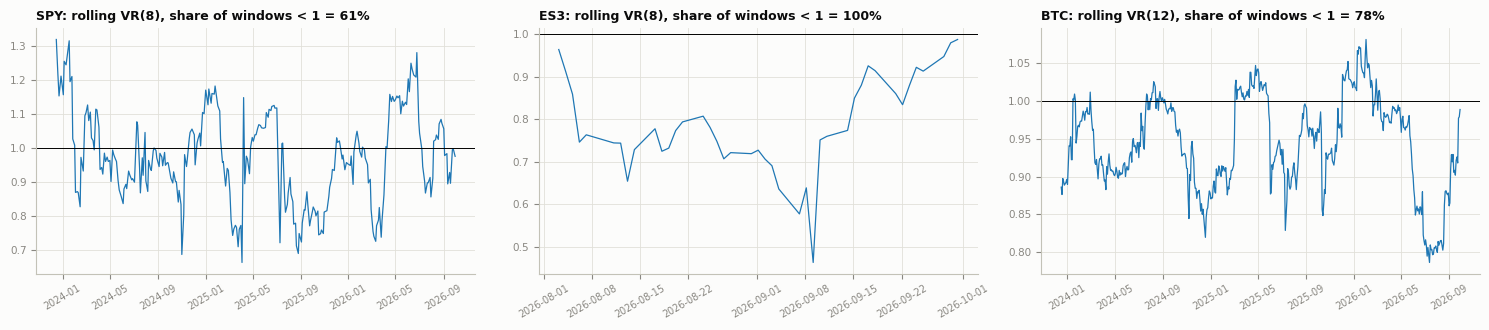

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
roll_share = {}
for k, (a, win, step) in enumerate((("SPY", 250, 10), ("ES3", 80, 4), ("BTC", 4320, 96))):
    r = D[a]["ret"].dropna()
    q = ASSETS[a]["main_h"]
    pts = range(win, len(r), step)
    s = pd.Series({r.index[i]: variance_ratio(r.iloc[i - win:i], q)[0] for i in pts})
    roll_share[a] = (s < 1).mean()
    ax[k].plot(s.index, s.values, lw=0.9)
    ax[k].axhline(1, color="k", lw=0.7)
    ax[k].set_title(f"{a}: rolling VR({q}), share of windows < 1 = {(s < 1).mean():.0%}", fontsize=9)
    ax[k].tick_params(axis="x", labelsize=7, rotation=30)
plt.tight_layout(); plt.show()

### Figure 6 — Evidence at a glance

Every test's signed statistic at each asset's main horizon (train), oriented so that **negative = MR side,
positive = momentum side**, coloured on the same blue–grey–red scale and clipped at ±3. Columns marked † are not in
the FE5209 slides (variance ratio, Hurst); the rest are from L4 / L5 / L2 + SDA.

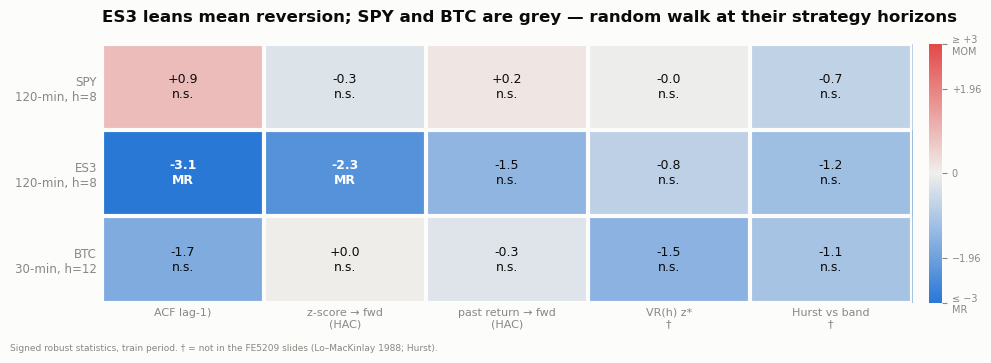

In [22]:
cols = ["ACF lag-1)", "z-score → fwd\n(HAC)", "past return → fwd\n(HAC)", "VR(h) z*\n†", "Hurst vs band\n†"]
M = np.zeros((3, len(cols))); TXT = [[""] * len(cols) for _ in range(3)]
for i, a in enumerate(ASSETS):
    h = ASSETS[a]["main_h"]
    acf1 = acf_tab[(acf_tab.asset == a) & (acf_tab.period == "train") & (acf_tab.lag == 1)].iloc[0]
    s = sig_tab[(sig_tab.asset == a) & (sig_tab.period == "train") & (sig_tab.h == h)]
    mr_t = s[s.test.str.startswith("MR")]["HAC t"].iloc[0]
    mo_t = s[s.test.str.startswith("MOM")]["HAC t"].iloc[0]
    q = h if h in ASSETS[a]["vr_q"] else ASSETS[a]["vr_q"][-2]
    vz = vr_tab[(vr_tab.asset == a) & (vr_tab.period == "train") & (vr_tab["q (bars)"] == q)]["z*"].iloc[0]
    hu = hurst_tab.loc[(a, "train")]
    hz = (hu["H"] - 0.5) / ((hu["RW band high"] - hu["RW band low"]) / (2 * 1.96))   # H in "band sigmas"
    vals = [acf1["HAC t"], mr_t, mo_t, vz, hz]
    for j, v in enumerate(vals):
        M[i, j] = v
        tag = "MR" if v < -1.96 else "MOM" if v > 1.96 else "n.s."
        TXT[i][j] = f"{v:+.1f}\n{tag}"
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(np.clip(M, -3, 3), cmap=DIV_CMAP, vmin=-3, vmax=3, aspect="auto")
for i in range(3):
    for j in range(len(cols)):
        strong = abs(M[i, j]) > 2.2
        ax.text(j, i, TXT[i][j], ha="center", va="center", fontsize=9,
                color="#ffffff" if strong else INK, fontweight="semibold" if abs(M[i, j]) > 1.96 else "normal")
ax.set_xticks(range(len(cols)), cols, fontsize=8)
ax.set_yticks(range(3), [f"{a}\n{ASSETS[a]['bar_minutes']}-min, h={ASSETS[a]['main_h']}" for a in ASSETS], fontsize=8.5)
ax.set_xticks(np.arange(-0.5, len(cols)), minor=True); ax.set_yticks(np.arange(-0.5, 3), minor=True)
ax.grid(which="minor", color=SURF, linewidth=3); ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for s_ in ax.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cb.set_ticks([-3, -1.96, 0, 1.96, 3], labels=["≤ −3\nMR", "−1.96", "0", "+1.96", "≥ +3\nMOM"]); cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=7, colors=MUTED)
ax.set_title("ES3 leans mean reversion; SPY and BTC are grey — random walk at their strategy horizons",
             fontsize=12, fontweight="bold", loc="left", pad=16)
finish(fig, "fig6_evidence_heatmap", "Signed robust statistics, train period. † = not in the FE5209 slides (Lo–MacKinlay 1988; Hurst).")

## 8. Verdict: mean reversion, momentum or random walk?

Built from the **train** numbers above at each asset's **main horizon** (SPY / ES3: 8 bars of 120 min ≈ 2 sessions;
BTC: 12 bars of 30 min = 6 h). Rule:

* a test counts as **MR** evidence if it is significantly on the MR side (|t| or |z\*| > 1.96, or Hurst outside the band),
  **MOM** if significantly on the momentum side, otherwise it only shows a *lean*;
* **verdict = MR / MOM** when at least two of the five tests are significant on that side and none on the other;
  **random walk** otherwise (the lean is reported in brackets).

In [23]:
def pick(df, **kw):
    for k, v in kw.items():
        df = df[df[k] == v]
    return df.iloc[0]


out = []
for a in ASSETS:
    h = ASSETS[a]["main_h"]
    acf1 = pick(acf_tab, asset=a, period="train", lag=1)
    vr = pick(vr_tab, asset=a, period="train", **{"q (bars)": h if h in ASSETS[a]["vr_q"] else ASSETS[a]["vr_q"][-2]})
    hu = hurst_tab.loc[(a, "train")]
    mr = sig_tab[(sig_tab.asset == a) & (sig_tab.period == "train") & (sig_tab.h == h) & sig_tab.test.str.startswith("MR")].iloc[0]
    mo = sig_tab[(sig_tab.asset == a) & (sig_tab.period == "train") & (sig_tab.h == h) & sig_tab.test.str.startswith("MOM")].iloc[0]
    tests = {
        "ACF lag-1": (acf1["rho"], acf1["HAC t"], -1),          # side: negative stat = MR
        f"VR({int(vr['q (bars)'])})": (vr["VR"] - 1, vr["z*"], -1),
        "Hurst": (hu["H"] - 0.5, -2.5 if hu["H"] < hu["RW band low"] else 2.5 if hu["H"] > hu["RW band high"] else 0.0, -1),
        mr["test"] + f", h={h}": (mr["beta"], mr["HAC t"], -1),
        mo["test"] + f", h={h}": (mo["beta"], mo["HAC t"], +1),  # positive slope = MOM
    }
    n_mr = n_mom = lean_mr = 0
    detail = []
    for name, (val, t, side) in tests.items():
        mr_side = val < 0          # every stat is signed so that negative = MR side (for the MOM regression: negative slope = reversal)
        sig = abs(t) > 1.96
        n_mr += sig and mr_side
        n_mom += sig and not mr_side
        lean_mr += mr_side
        detail.append(f"{name}: {'MR' if mr_side else 'MOM'}{' (sig.)' if sig else ''}")
    if n_mr >= 2 and n_mom == 0:
        verdict = "MEAN REVERSION"
    elif n_mom >= 2 and n_mr == 0:
        verdict = "MOMENTUM"
    else:
        verdict = f"RANDOM WALK (leans {'MR' if lean_mr >= 3 else 'MOM'}, {lean_mr}/5 tests on the MR side)"
    out.append({"asset": a, "bar": f"{ASSETS[a]['bar_minutes']} min", "traded strategy": ASSETS[a]["strategy"],
                "train bars": len(sl(D[a]["ret"], a, "train").dropna()),
                "sig. MR tests": int(n_mr), "sig. MOM tests": int(n_mom), "diagnostic verdict": verdict,
                "detail": "; ".join(detail)})
verdict_tab = pd.DataFrame(out).set_index("asset")
verdict_tab

,bar,traded strategy,train bars,sig. MR tests,sig. MOM tests,diagnostic verdict,detail
asset,,,,,,,
SPY,120 min,momentum (long/cash),2033,0,0,"RANDOM WALK (leans MR, 3/5 tests on the MR side)","ACF lag-1: MOM; VR(8): MR; Hurst: MR; MR: z(W=16), h=8: MR; MOM: R(L=8), h=8: MOM"
ES3,120 min,mean reversion (long/cash),159,2,0,MEAN REVERSION,"ACF lag-1: MR (sig.); VR(8): MR; Hurst: MR; MR: z(W=16), h=8: MR (sig.); MOM: R(L=8), h=8: MR"
BTC,30 min,voting: BB/stoch reversal + 12-bar return/volume momentum (long/short),47423,0,0,"RANDOM WALK (leans MR, 4/5 tests on the MR side)","ACF lag-1: MR; VR(12): MR; Hurst: MR; MR: z(W=20), h=12: MOM; MOM: R(L=12), h=12: MR"


## 9. What this means for each strategy

*(Written after running on `market_bars_30m_through_261012.csv`, data up to 2026-09-30. Re-read the tables if the data changes.)*

| asset | bar / horizon tested | traded strategy | diagnostic verdict | does the evidence support the traded family? |
|---|---|---|---|---|
| **SPY** | 120 min, h = 8 bars (≈ 2 sessions) | momentum | **Random walk** | **No, but it doesn't contradict it either.** No momentum evidence. |
| **ES3** | 120 min, h = 8–20 bars | mean reversion | **Mean reversion** (weak, small sample) | **Yes.** |
| **BTC** | 30 min, h = 12 bars (6 h) | voting (reversal + momentum votes) | **Random walk** (in direction) | **Neither leg on its own.** The edge has to come from the volatility gate / volume, not from MR or MOM. |

**SPY: random walk at 120 min.** Not one test is significant on ~2,000 train bars: lag-1 ρ = +0.04 (t = 0.9),
VR(8) = 0.99, Hurst 0.48 inside the random-walk band (0.45–0.55), and the momentum regression (8-bar return → next 8 bars)
has t = 0.16 on train and −1.41 on validation. The exact traded rule (EMA 8 > EMA 16 and 8-bar return > 0.25 %) earns
+12 bps per entry over 8 bars, but **−5 bps relative to a random long entry** on train and +1 bps on validation: what it
captures is SPY's upward drift while being long, not continuation. For the report: say the momentum rule is a **low-cost trend-following / exposure-timing choice** (round trip
≈ 0.1 bps) selected on after-cost validation return, and that the diagnostics show SPY at this horizon is close to a
random walk. Don't claim the diagnostics prove momentum.

**ES3: mean reversion, the only asset where the traded family is supported.** Lag-1 autocorrelation is −0.11
(HAC t = −3.1), VR < 1 at every horizon (0.66–0.90, not individually significant), Hurst 0.42 (inside the wide band of a
159-bar sample), and the z(16) → forward-return slope is negative at every horizon and significant at h = 8, 16, 20
(t = −2.1 to −2.6). Momentum signals point the other way (negative slopes, and the momentum rule loses −11 to −18 bps vs
drift). The traded entry (z ≤ −1.25) gained +64 bps over drift in 8 bars on train, well above the 16 bps cost.
**Caveats to state:** train is only 2026-07-06 → 08-31 (Yahoo intraday limit), the rule fired **7 times on train and
3 on validation**, and validation signs agree but are not significant. "Consistent with MR, small sample."

**BTC: random walk in direction at 30 min.** On 47,000 train bars VR(12) = 0.95 (z\* = −1.5), Hurst 0.493 inside a very
tight band (0.487–0.511), lag-1 ρ = −0.02 (t = −1.7); the z(20) and 12-bar-return regressions are both insignificant
(t = 0.04 and −0.28). The price ingredients of the voting rule, tested on their own: reversal leg (%B ≤ 0.1 and
stoch ≤ 30) +3.4 bps per trade, momentum leg (12-bar return sign) −0.3 bps, both agreeing −0.2 bps, all far below the
20 bps round trip. For the report: the voting strategy's result must come from **combining the votes with the
volatility-model gate and volume filter** (the reversal votes acting as a filter on overextended momentum entries), and
its out-of-sample trade count is small; it is not justified by MR or MOM diagnostics alone.